In [1]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

model_path = "../models/face_landmarker.task"

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1
)

detector = vision.FaceLandmarker.create_from_options(options)

In [3]:
def get_landmark_coordinates(landmarks, indices, width, height):

    points = []

    for index in indices:

        x = int(landmarks[index].x * width)
        y = int(landmarks[index].y * height)

        points.append([x, y])

    return np.array(points)

In [4]:
def euclidean_distance(point1, point2):

    return np.linalg.norm(point1 - point2)

In [5]:
p1 = np.array([10, 20])
p2 = np.array([40, 60])

print(euclidean_distance(p1, p2))

50.0


In [10]:
def calculate_ear(eye):

    A = euclidean_distance(eye[1], eye[5])
    B = euclidean_distance(eye[2], eye[4])
    C = euclidean_distance(eye[0], eye[3])

    ear = (A + B) / (2.0 * C)

    return ear

In [14]:
cap = cv2.VideoCapture(0)

ret, frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Could not capture image")

rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

h, w, _ = frame.shape

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_frame
)

results = detector.detect(mp_image)

In [15]:
if results.face_landmarks:

    landmarks = results.face_landmarks[0]

    right_eye_indices = [362, 385, 387, 263, 373, 380]
    left_eye_indices = [33, 160, 158, 133, 153, 144]

    right_eye = get_landmark_coordinates(
        landmarks, right_eye_indices, w, h
    )

    left_eye = get_landmark_coordinates(
        landmarks, left_eye_indices, w, h
    )

    right_ear = calculate_ear(right_eye)
    left_ear = calculate_ear(left_eye)

    avg_ear = (right_ear + left_ear) / 2

    print("Right EAR:", round(right_ear, 3))
    print("Left EAR:", round(left_ear, 3))
    print("Average EAR:", round(avg_ear, 3))

else:
    print("No face detected")

Right EAR: 0.354
Left EAR: 0.35
Average EAR: 0.352


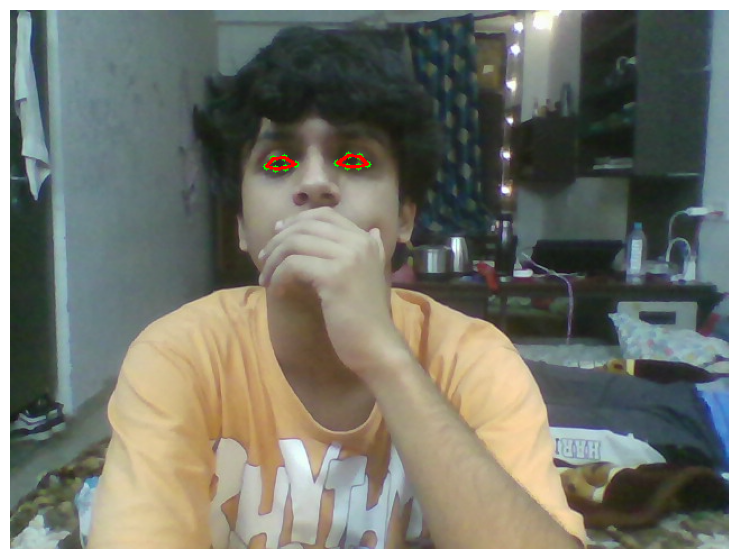

In [16]:
annotated = rgb_frame.copy()

for eye in [right_eye, left_eye]:

    for point in eye:
        cv2.circle(
            annotated,
            tuple(point),
            3,
            (0, 255, 0),
            -1
        )

    cv2.polylines(
        annotated,
        [eye],
        isClosed=True,
        color=(255, 0, 0),
        thickness=2
    )

plt.figure(figsize=(12, 7))
plt.imshow(annotated)
plt.axis("off");

In [17]:
EAR_THRESHOLD = 0.20

if avg_ear < EAR_THRESHOLD:
    eye_state = "CLOSED"
else:
    eye_state = "OPEN"

print("Eye State:", eye_state)

Eye State: OPEN
